<a href="https://colab.research.google.com/github/fraaaa25/Proyek-Kelompok-AVD/blob/main/Global_E_Commerce_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kelompok 3 :    
- Afra Haura Adzkiya Rahma / 01
- Ciara Martiandini / 07
- Hanelra Amaytus Tian / 21
- Filzia Zaafarani Maritza / 19

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Upload dataset
from google.colab import files
uploaded = files.upload()

# Membaca dataset
nama_file = list(uploaded.keys())[0]
df = pd.read_csv(nama_file)

# Menampilkan 5 data pertama
df.head()


Saving global_ecommerce_sales.csv to global_ecommerce_sales (1).csv


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


Eksplorasi dan Pembersihan Data

In [21]:
# Mengubah kolom Order_Date menjadi format tanggal
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')

# Melihat informasi dataset
print("Informasi Dataset:")
df.info()

# Melihat statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe())

# Memeriksa data kosong
print("\nJumlah Data Kosong:")
print(df.isnull().sum())

# Memeriksa jumlah seluruh data duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

# Memeriksa ID pesanan yang duplikat
print("\nJumlah Order ID Duplikat:")
print(df['Order_ID'].duplicated().sum())

# Memeriksa tanggal yang tidak valid
print("\nJumlah Tanggal Tidak Valid:")
print(df['Order_Date'].isnull().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          2000 non-null   object        
 1   Order_Date        2000 non-null   datetime64[ns]
 2   Customer_Name     2000 non-null   object        
 3   Customer_Segment  2000 non-null   object        
 4   Country           2000 non-null   object        
 5   Region            2000 non-null   object        
 6   Product_Category  2000 non-null   object        
 7   Product_Name      2000 non-null   object        
 8   Quantity          2000 non-null   int64         
 9   Unit_Price        2000 non-null   float64       
 10  Discount_Percent  2000 non-null   int64         
 11  Total_Sales       2000 non-null   float64       
 12  Shipping_Cost     2000 non-null   float64       
 13  Profit            2000 non-null   float64       
 14  Payme

,Order_Date,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit
count,2000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,2024-07-12 03:17:16.800000,3.557500,73.329490,8.572500,242.279670,12.90212,79.436160
min,2023-01-02 00:00:00,1.000000,3.030000,0.000000,2.420000,5.52000,-11.280000
25%,2023-10-08 00:00:00,2.000000,18.757500,0.000000,41.227500,9.45750,6.865000
50%,2024-07-12 12:00:00,3.000000,46.420000,10.000000,113.125000,11.84500,32.830000
75%,2025-04-20 06:00:00,5.000000,90.250000,15.000000,266.552500,14.92000,90.297500
max,2025-12-31 00:00:00,15.000000,472.560000,30.000000,3813.980000,40.44000,1373.630000
std,NaN,2.704506,79.311014,7.261274,382.583802,5.22319,137.573593



Jumlah Data Kosong:
Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       0
Profit              0
Payment_Method      0
dtype: int64

Jumlah Data Duplikat:
0

Jumlah Order ID Duplikat:
0

Jumlah Tanggal Tidak Valid:
0


Menghitung Statistik

In [22]:

# Menghitung statistik deskriptif Total_Sales
mean_sales = df['Total_Sales'].mean()
median_sales = df['Total_Sales'].median()
mode_sales = df['Total_Sales'].mode()[0]
std_sales = df['Total_Sales'].std()
var_sales = df['Total_Sales'].var()

min_sales = df['Total_Sales'].min()
max_sales = df['Total_Sales'].max()
range_sales = max_sales - min_sales

q1 = df['Total_Sales'].quantile(0.25)
q2 = df['Total_Sales'].quantile(0.50)
q3 = df['Total_Sales'].quantile(0.75)
iqr = q3 - q1

# Menampilkan hasil
print("STATISTIK DESKRIPTIF TOTAL SALES")
print("Mean (Rata-rata):", mean_sales)
print("Median (Nilai Tengah):", median_sales)
print("Mode (Nilai yang Sering Muncul):", mode_sales)
print("Standar Deviasi:", std_sales)
print("Varians:", var_sales)
print("Nilai Minimum:", min_sales)
print("Nilai Maksimum:", max_sales)
print("Range (Jangkauan):", range_sales)
print("Q1 (Kuartil 1):", Q1)
print("Q2 (Kuartil 2):", Q2)
print("Q3 (Kuartil 3):", Q3)
print("IQR:", iqr)

STATISTIK DESKRIPTIF TOTAL SALES
Mean (Rata-rata): 242.27966999999998
Median (Nilai Tengah): 113.125
Mode (Nilai yang Sering Muncul): 7.02
Standar Deviasi: 382.5838022343044
Varians: 146370.36573205734
Nilai Minimum: 2.42
Nilai Maksimum: 3813.98
Range (Jangkauan): 3811.56
Q1 (Kuartil 1): 41.2275
Q2 (Kuartil 2): 113.125
Q3 (Kuartil 3): 266.5525
IQR: 225.32500000000002


In [23]:
# Total penjualan
total_penjualan = df['Total_Sales'].sum()

# Rata-rata transaksi
rata_transaksi = df['Total_Sales'].mean()

# Total profit
total_profit = df['Profit'].sum()

# Penjualan berdasarkan kategori
total_kategori = df.groupby('Product_Category')['Total_Sales'].sum()

# Kategori dengan penjualan tertinggi
kategori_terlaris = total_kategori.idxmax()

# Penjualan berdasarkan wilayah
total_wilayah = df.groupby('Region')['Total_Sales'].sum()

# Wilayah dengan penjualan tertinggi
wilayah_teratas = total_wilayah.idxmax()

print("=== RINGKASAN STATISTIK ===")
print("Total Penjualan: $", round(total_penjualan, 2))
print("Rata-rata Transaksi: $", round(rata_transaksi, 2))
print("Total Profit: $", round(total_profit, 2))
print("Kategori Terlaris:", kategori_terlaris)
print("Wilayah Teratas:", wilayah_teratas)

=== RINGKASAN STATISTIK ===
Total Penjualan: $ 484559.34
Rata-rata Transaksi: $ 242.28
Total Profit: $ 158872.32
Kategori Terlaris: Furniture
Wilayah Teratas: Europe


Visualisasi

Bar Chart

/tmp/ipykernel_507/1511452720.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


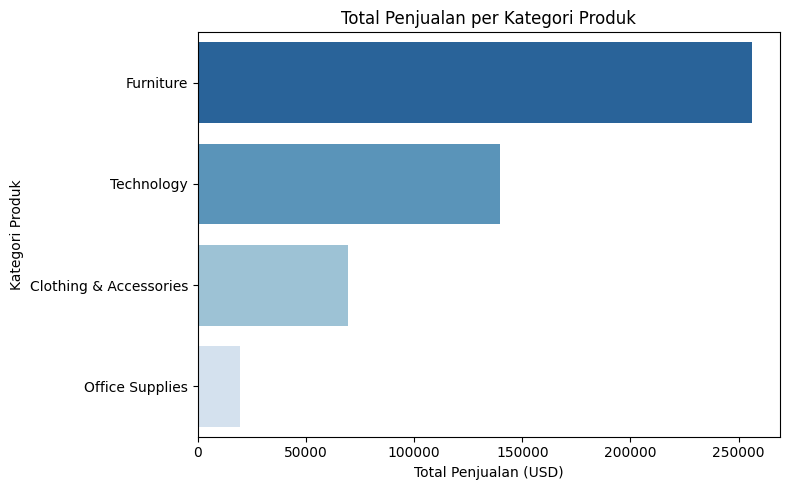

In [24]:
total_kategori = df.groupby('Product_Category')['Total_Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')

plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (USD)')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

Line Chart

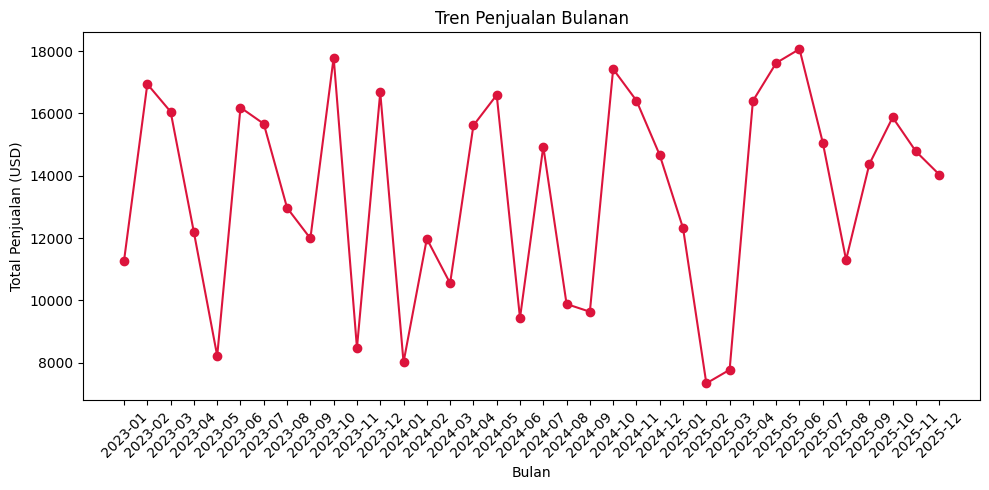

Penjualan tertinggi:
2025-06 18068.09
Penjualan terendah:
2025-02 7337.28


In [26]:
df['bulan'] = df['Order_Date'].dt.to_period('M')

tren_bulanan = df.groupby('bulan')['Total_Sales'].sum()

plt.figure(figsize=(10,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')

plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (USD)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Penjualan tertinggi:")
print(tren_bulanan.idxmax(), tren_bulanan.max())

print("Penjualan terendah:")
print(tren_bulanan.idxmin(), tren_bulanan.min())

Scatter Plot

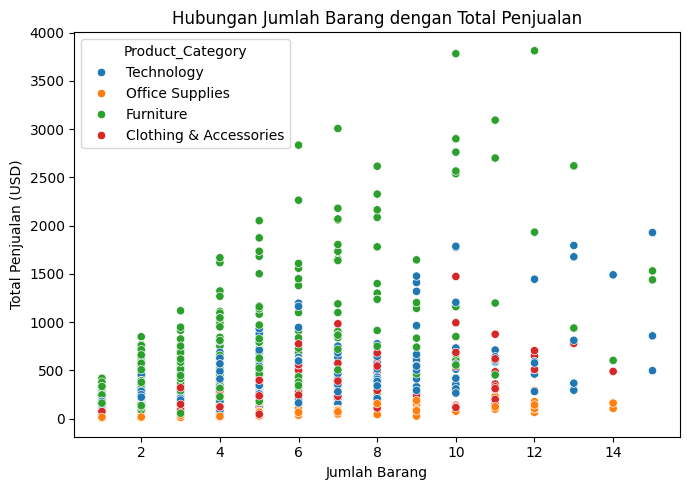

Korelasi Quantity dan Total_Sales: 0.5032330095315908


In [27]:
plt.figure(figsize=(7,5))

sns.scatterplot(data=df, x='Quantity', y='Total_Sales', hue='Product_Category')

plt.title('Hubungan Jumlah Barang dengan Total Penjualan')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total Penjualan (USD)')

plt.tight_layout()
plt.show()

print("Korelasi Quantity dan Total_Sales:",
      df['Quantity'].corr(df['Total_Sales']))

Histogram

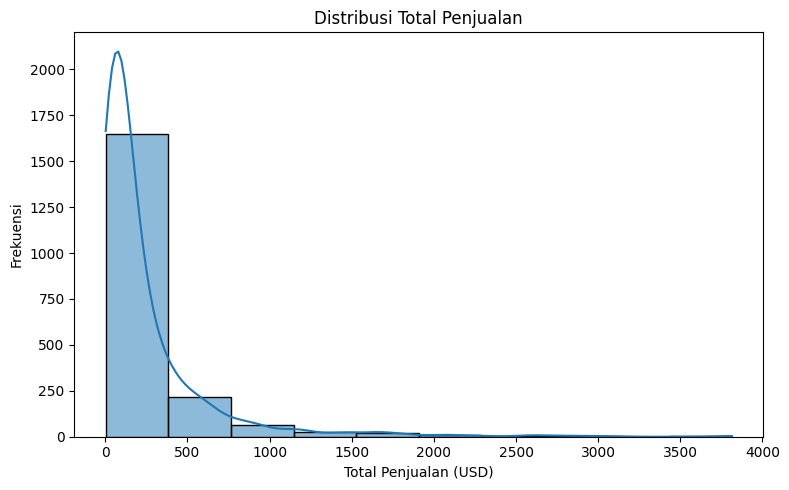

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(df['Total_Sales'], bins=10, kde=True)

plt.title('Distribusi Total Penjualan')
plt.xlabel('Total Penjualan (USD)')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

Visualisasi Boxplot dan Deteksi Outlier

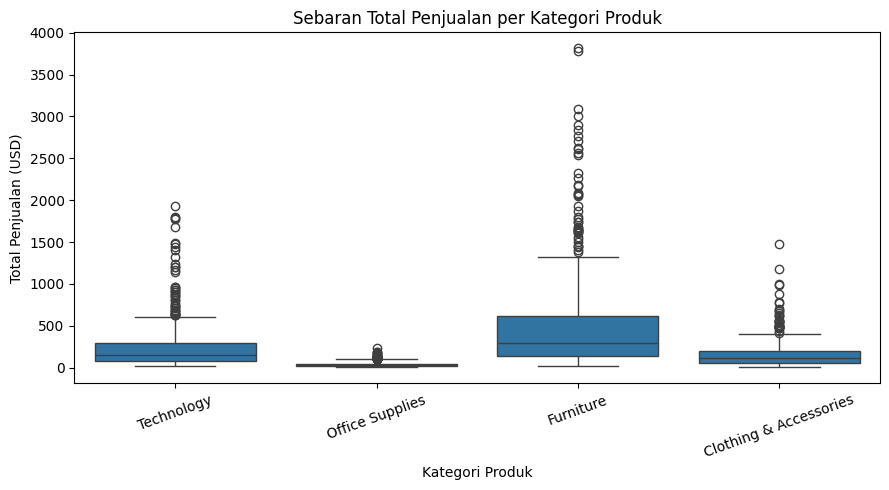

Batas Bawah: -296.76
Batas Atas: 604.54
Jumlah Outlier: 190
     Order_ID Product_Category  Total_Sales
4   ORD-11454        Furniture      1058.14
8   ORD-11702        Furniture       634.81
16  ORD-11886        Furniture       914.43
17  ORD-10339        Furniture       848.92
24  ORD-11128        Furniture      1501.15


In [29]:
plt.figure(figsize=(9,5))

sns.boxplot(data=df, x='Product_Category', y='Total_Sales')

plt.title('Sebaran Total Penjualan per Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Penjualan (USD)')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Menghitung batas outlier menggunakan IQR
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Menampilkan data outlier
outlier = df[(df['Total_Sales'] < batas_bawah) | (df['Total_Sales'] > batas_atas)]

print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)
print("Jumlah Outlier:", len(outlier))

print(outlier[['Order_ID', 'Product_Category', 'Total_Sales']].head())

### Interpretasi Hasil Analisis Outlier

Berdasarkan metode Interquartile Range (IQR), diperoleh hasil sebagai berikut:

- Q1 (Kuartil 1) = 41,23 USD
- Q3 (Kuartil 3) = 266,55 USD
- IQR = $225,33
- Batas bawah = -296,76 USD
- Batas atas = 604,54 USD

Dari hasil tersebut, transaksi dengan nilai Total_Sales di atas $604,54 teridentifikasi sebagai potensi outlier. Terdapat **190 transaksi** yang termasuk dalam kategori tersebut.

Outlier ini menunjukkan adanya beberapa transaksi dengan nilai penjualan yang jauh lebih tinggi dibandingkan sebagian besar transaksi lainnya. Hal tersebut belum tentu merupakan kesalahan data, karena dapat disebabkan oleh pembelian barang dalam jumlah banyak atau produk dengan harga tinggi.

Oleh karena itu, transaksi yang teridentifikasi sebagai outlier perlu diperiksa lebih lanjut sebelum dilakukan tindakan terhadap data tersebut.

Membuat Dashboard 4 Grafik dalam 1 Figure

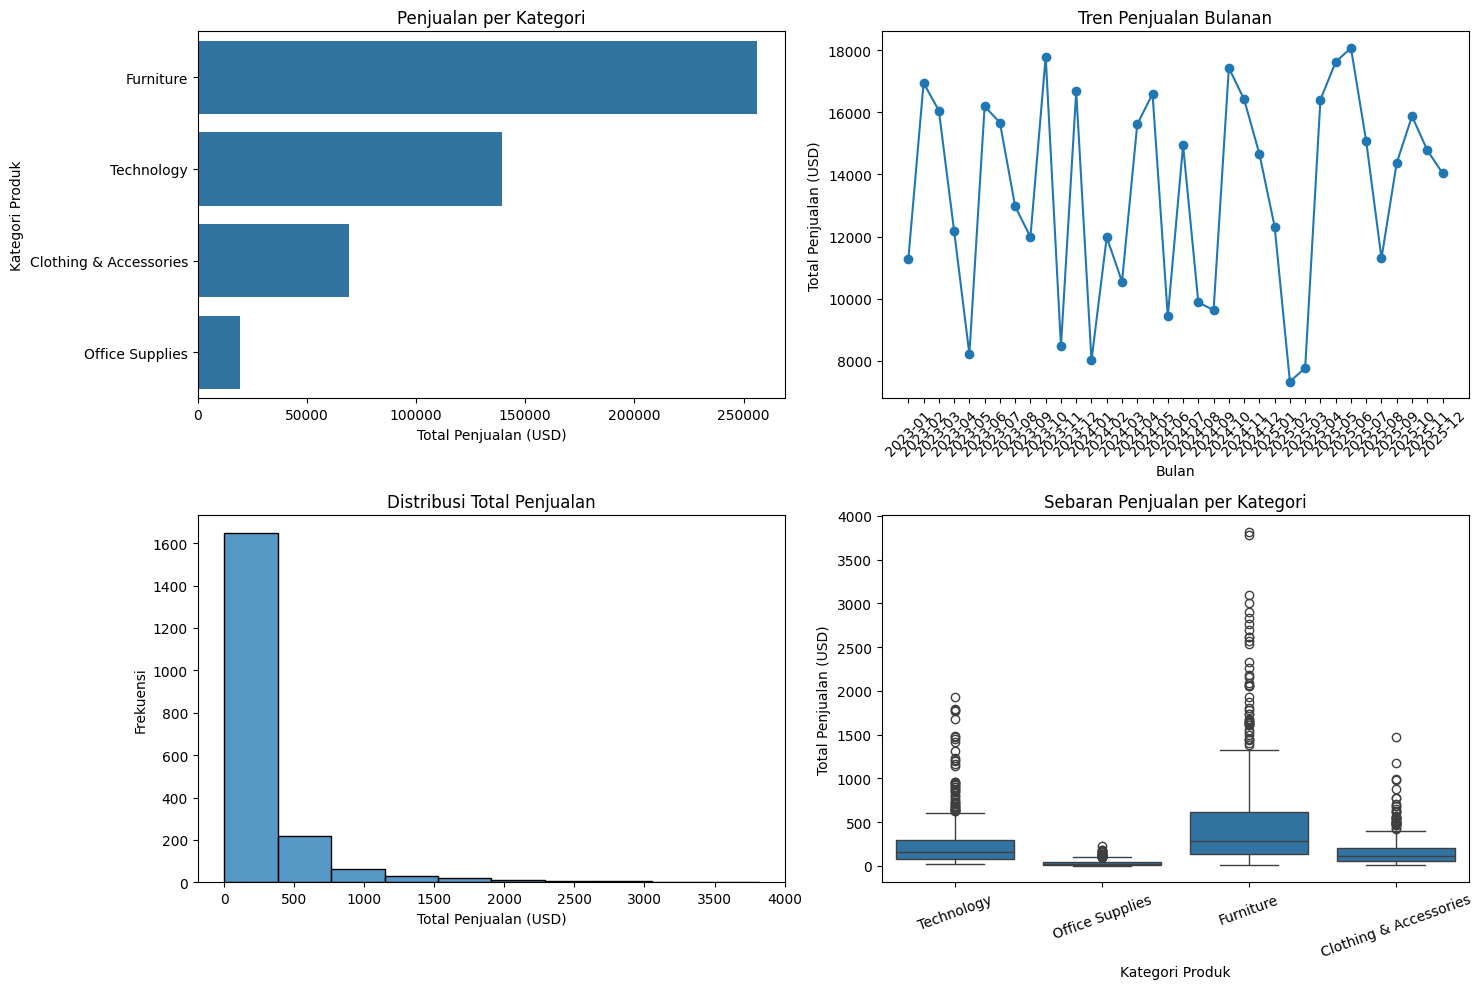

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(15,10))

# Grafik 1: Bar Chart
sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Penjualan per Kategori')
axes[0,0].set_xlabel('Total Penjualan (USD)')
axes[0,0].set_ylabel('Kategori Produk')

# Grafik 2: Line Chart
axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')
axes[0,1].set_xlabel('Bulan')
axes[0,1].set_ylabel('Total Penjualan (USD)')
axes[0,1].tick_params(axis='x', rotation=45)

# Grafik 3: Histogram
sns.histplot(df['Total_Sales'], bins=10, ax=axes[1,0])
axes[1,0].set_title('Distribusi Total Penjualan')
axes[1,0].set_xlabel('Total Penjualan (USD)')
axes[1,0].set_ylabel('Frekuensi')

# Grafik 4: Boxplot
sns.boxplot(data=df, x='Product_Category', y='Total_Sales', ax=axes[1,1])
axes[1,1].set_title('Sebaran Penjualan per Kategori')
axes[1,1].set_xlabel('Kategori Produk')
axes[1,1].set_ylabel('Total Penjualan (USD)')
axes[1,1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# LAPORAN ANALISIS DATA PENJUALAN E-COMMERCE

## 1. Ringkasan Statistik

- **Total Penjualan:** 484.559,34 USD
- **Rata-rata Transaksi:** 242,28 USD
- **Kategori Terlaris:** Furniture
- **Wilayah Teratas:** Europe
- **Total Profit:** $158.872,32

## 2. Temuan Utama (Insight)

## 2. Temuan Utama (Insight)

- **Bar Chart:** Kategori Furniture memiliki total penjualan tertinggi sebesar 256.274,68 USD. Sementara itu, Office Supplies memiliki total penjualan terendah sebesar 19.390,81 USD. Hal ini menunjukkan bahwa Furniture memberikan kontribusi penjualan terbesar dibandingkan kategori lainnya.

- **Line Chart:** Grafik menunjukkan bahwa penjualan mengalami perubahan setiap bulan selama periode 2023–2025. Perubahan tersebut menunjukkan bahwa pendapatan perusahaan tidak selalu stabil setiap bulannya sehingga perlu dilakukan pemantauan secara berkala.

- **Scatter Plot:** Grafik menunjukkan hubungan antara jumlah barang yang dibeli (Quantity) dengan total penjualan (Total_Sales). Grafik ini dapat digunakan untuk mengamati apakah pembelian dalam jumlah lebih banyak cenderung menghasilkan nilai transaksi yang lebih tinggi.

- **Histogram:** Rata-rata penjualan sebesar 242,28 USD lebih tinggi dibandingkan nilai median sebesar 113,13 USD. Hal ini menunjukkan bahwa distribusi nilai transaksi cenderung miring ke kanan karena terdapat beberapa transaksi dengan nilai penjualan yang tinggi.

- **Boxplot:** Berdasarkan grafik dan perhitungan IQR, terdapat transaksi dengan nilai penjualan yang jauh lebih tinggi dibandingkan sebagian besar transaksi lainnya. Hal ini menunjukkan adanya potensi outlier dalam data penjualan.

## 3. Potensi Outlier

Berdasarkan perhitungan IQR, terdapat transaksi dengan nilai penjualan yang jauh lebih tinggi dibandingkan sebagian besar transaksi lainnya. Potensi outlier tersebut dapat terjadi karena pembelian barang dalam jumlah banyak atau transaksi produk dengan harga tinggi.

## 4. Rekomendasi Bisnis

Berdasarkan hasil analisis data penjualan e-commerce, terdapat beberapa strategi bisnis yang dapat dilakukan untuk meningkatkan penjualan dan keuntungan perusahaan.

Pertama, perusahaan perlu mempertahankan dan mengembangkan kategori produk Furniture karena memiliki total penjualan tertinggi dibandingkan kategori lainnya. Perusahaan dapat menyediakan stok produk yang cukup, menjaga kualitas produk, serta memberikan promosi menarik agar pelanggan tetap tertarik untuk membeli.

Kedua, perusahaan dapat meningkatkan penjualan kategori Office Supplies karena kategori ini memiliki total penjualan paling rendah. Strategi yang dapat dilakukan adalah memberikan diskon khusus, membuat paket pembelian, dan menawarkan produk tersebut kepada pelanggan yang membutuhkan perlengkapan kantor.

Ketiga, perusahaan perlu memperhatikan wilayah Europe karena memiliki total penjualan tertinggi. Perusahaan dapat mempertahankan pelayanan dan ketersediaan produk di wilayah tersebut. Selain itu, wilayah dengan penjualan lebih rendah dapat menjadi target promosi agar penjualannya meningkat.

Keempat, perusahaan perlu mengevaluasi transaksi yang menghasilkan profit negatif. Hal ini dapat dilakukan dengan memeriksa pemberian diskon, harga produk, dan biaya pengiriman agar perusahaan tidak mengalami kerugian pada terlalu banyak transaksi.

Terakhir, perusahaan perlu memantau perubahan penjualan setiap bulan untuk mengetahui waktu ketika penjualan meningkat atau menurun. Hasil pemantauan tersebut dapat digunakan untuk menentukan waktu promosi dan mengatur persediaan barang.

Dengan menerapkan strategi tersebut, perusahaan diharapkan dapat meningkatkan penjualan, mengurangi kerugian, dan memperoleh keuntungan yang lebih baik.